In [ ]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.path.dirname(__file__), '..')))

import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
from utils import price_dict_to_df
plt.style.use('dark_background')

In [ ]:
datas = joblib.load('/Users/leoinv/Documents/CODE/BACKTEST/data/1h.joblib')
close = price_dict_to_df(datas)
volume = price_dict_to_df(datas, 'volume')

min_valid_rows = 20000
valid_cols = close.columns[close.notna().sum() >= min_valid_rows]
close = close[valid_cols].ffill()
volume = volume[valid_cols].ffill()

rets = np.log(close).diff().fillna(0).values
rets_fwd = np.roll(rets, -1, axis=0)
rets_fwd[-1, :] = 0

vol = volume.values
n_steps, n_assets = vol.shape
index = volume.index

split_ratio = 0.8  # 70% train, 30% test
split_idx = int(n_steps * split_ratio)

vol_train = vol[:split_idx]
close_train = close.values[:split_idx]
rets_fwd_train = rets_fwd[:split_idx]

vol_test = vol[split_idx:]
close_test = close.values[split_idx:]
rets_fwd_test = rets_fwd[split_idx:]
index_train = index[:split_idx]
index_test = index[split_idx:]

Data is ready
Data is ready


In [ ]:
@njit
def nanmean_axis0(arr):
    n_rows, n_cols = arr.shape
    means = np.empty(n_cols)
    for j in range(n_cols):
        s = 0.0
        count = 0
        for i in range(n_rows):
            if not np.isnan(arr[i, j]):
                s += arr[i, j]
                count += 1
        means[j] = s / count if count > 0 else np.nan
    return means

@njit(parallel=True)
def compute_factor_hourly(vol, rets_fwd, close, diff_score, rebalance_freq, long_n,
                          fee_rate=0.0005):
    n_steps, n_assets = vol.shape
    results = np.zeros(n_steps)
    window = int(rebalance_freq / 2.7)

    for i in prange(2*rebalance_freq, n_steps - rebalance_freq):
        if (i - 2*rebalance_freq) % rebalance_freq != 0:
            continue

        past_vol = vol[i - 2*rebalance_freq:i]
        past_close = close[i - 2*rebalance_freq:i]

        zscores = np.empty((2*rebalance_freq, n_assets))
        zscores[:] = np.nan
        price_vs_sma = np.empty(n_assets)
        price_vs_sma[:] = np.nan
        vola_score = np.empty(n_assets)
        vola_score[:] = np.nan
        momentum_score = np.empty(n_assets)
        momentum_score[:] = np.nan

        for asset in range(n_assets):
            v = past_vol[:, asset]
            c = past_close[:, asset]

            # ---- Volume Z-score ----
            ma = np.empty(len(v))
            ma[:] = np.nan
            sd = np.empty(len(v))
            sd[:] = np.nan
            for t in range(window-1, len(v)):
                slice_ = v[t+1-window:t+1]
                mean_ = np.mean(slice_)
                std_ = np.std(slice_)
                ma[t] = mean_
                sd[t] = std_ if std_ > 1e-12 else 1e-12
            zscores[:, asset] = (v - ma) / sd

            # ---- Price vs SMA ----
            if len(c) >= window:
                sma_val = np.mean(c[-window:])
                if sma_val > 1e-12:
                    price_vs_sma[asset] = (c[-1] / sma_val) - 1.0

            # ---- Volatility (std of returns) ----
            if len(c) >= window:
                log_ret = np.diff(np.log(c[-window:]))
                if len(log_ret) > 1:
                    vola_score[asset] = np.std(log_ret)

            # ---- Momentum ----
            if len(c) >= window:
                momentum_score[asset] = (c[-1] / c[-window]) - 1.0

        def rank_array(arr):
            ranks = np.empty_like(arr)
            valid_idx = ~np.isnan(arr)
            vals = arr[valid_idx]
            order = np.argsort(vals)
            ranks[valid_idx] = np.argsort(order)  # rank 0 = worst
            ranks[~valid_idx] = -1
            return ranks


        last_period = zscores[-rebalance_freq:]
        mean_z = nanmean_axis0(last_period)
        
        # Rank each factor
        rank_z = rank_array(mean_z)
        rank_ps = rank_array(price_vs_sma)
        rank_vola = rank_array(vola_score)  # invert: lower vol is better
        rank_mom = rank_array(momentum_score)

        # Combine ranks
        combined_score = np.full(n_assets, -1e12)
        for a in range(n_assets):
            score = 0.0
            cnt = 0
            if rank_z[a] >= 0:
                score += rank_z[a]
                cnt += 1
            if rank_ps[a] >= 0:
                score += rank_ps[a]
                cnt += 1
            if rank_vola[a] >= 0:
                score += rank_vola[a]
                cnt += 1
            if rank_mom[a] >= 0:
                score += rank_mom[a]
                cnt += 1

            combined_score[a] = score / cnt if cnt > 0 else -1e12

        # Exclude BTC (index 0)
        ranked_idx = np.argsort(combined_score)
        valid_assets = ranked_idx[ranked_idx != 0]
        if valid_assets.size < long_n:
            continue
        top_assets = valid_assets[-long_n:]

        # Compute basket vs BTC signal
        basket_score = np.nanmean(combined_score[top_assets])
        btc_score = combined_score[0]

        # Determine long direction
        go_long_basket = basket_score >= btc_score + diff_score

        fee_cost = fee_rate
        trade_idx = np.arange(i, i+rebalance_freq)

        for j, t in enumerate(trade_idx):
            basket_r = np.nanmean(rets_fwd[t, top_assets])
            btc_r = rets_fwd[t, 0]
            ret = (basket_r - btc_r) if go_long_basket else (btc_r - basket_r)
            if j == 0:
                ret -= fee_cost
            results[t] = ret

    return results

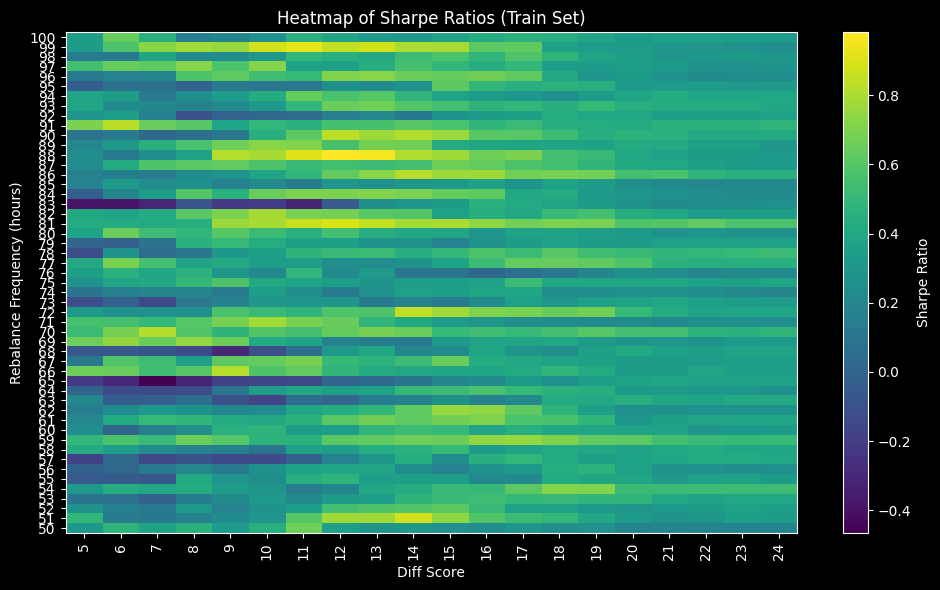

In [ ]:
rebalance_freqs = np.arange(50, 101, 1)
diff_scores = np.arange(5, 25, 1)

sharpe_train = {}
for d in diff_scores:
    for rf in rebalance_freqs:
        factor_arr = compute_factor_hourly(
            vol=vol_train, close=close_train,
            rets_fwd=rets_fwd_train, diff_score=d, rebalance_freq=rf,
            long_n=10, fee_rate=0.0005
        )
        sharpe_train[(rf, d)] = factor_arr.mean() / np.sqrt(np.var(factor_arr)) * np.sqrt(365*24)

sharpe_df = pd.DataFrame.from_dict(sharpe_train, orient='index', columns=['Sharpe'])
sharpe_df.index = pd.MultiIndex.from_tuples(sharpe_df.index, names=["Rebalance", "Diff_Score"])
sharpe_pivot = sharpe_df['Sharpe'].unstack()

plt.figure(figsize=(10, 6))
plt.imshow(sharpe_pivot.values, aspect='auto', origin='lower', cmap='viridis')
plt.colorbar(label='Sharpe Ratio')
plt.xticks(ticks=np.arange(len(sharpe_pivot.columns)), labels=sharpe_pivot.columns, rotation=90)
plt.yticks(ticks=np.arange(len(sharpe_pivot.index)), labels=sharpe_pivot.index)
plt.xlabel("Diff Score")
plt.ylabel("Rebalance Frequency (hours)")
plt.title("Heatmap of Sharpe Ratios (Train Set)")
plt.tight_layout()
plt.show()

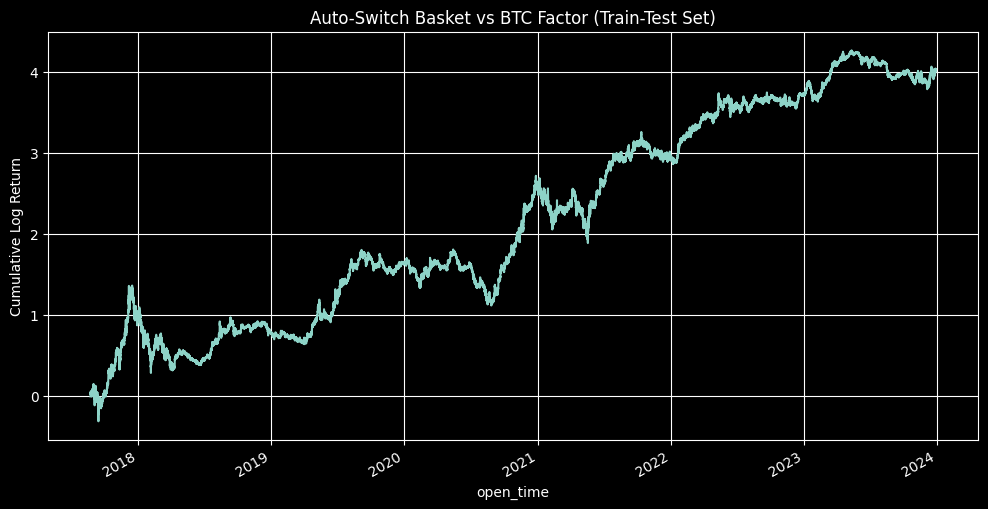

0.9765981385436329


In [ ]:
threshold = sharpe_df['Sharpe'].quantile(0.90)
robust_candidates = sharpe_df[sharpe_df['Sharpe'] > threshold]
best_rf = robust_candidates.groupby(level=0)['Sharpe'].mean().idxmax()
best_d = robust_candidates.groupby(level=1)['Sharpe'].mean().idxmax()

factor_arr = compute_factor_hourly(
    vol=vol_train, close=close_train,
    rets_fwd=rets_fwd_train, diff_score=best_d,
    rebalance_freq=best_rf,
    long_n=10,
    fee_rate=0.0005
)

start = 2 * best_rf
end = vol_train.shape[0] - best_rf
factor_rets = pd.Series(factor_arr[start:end], index=index_train[start:end], name="factor_return")

cum_factor = factor_rets.cumsum()
plt.figure(figsize=(12, 6))
cum_factor.plot()
plt.title("Auto-Switch Basket vs BTC Factor (Train-Test Set)")
plt.ylabel("Cumulative Log Return")
plt.grid(True)
plt.show()

print(factor_rets.mean() / np.sqrt(np.var(factor_rets)) * np.sqrt(365*24))

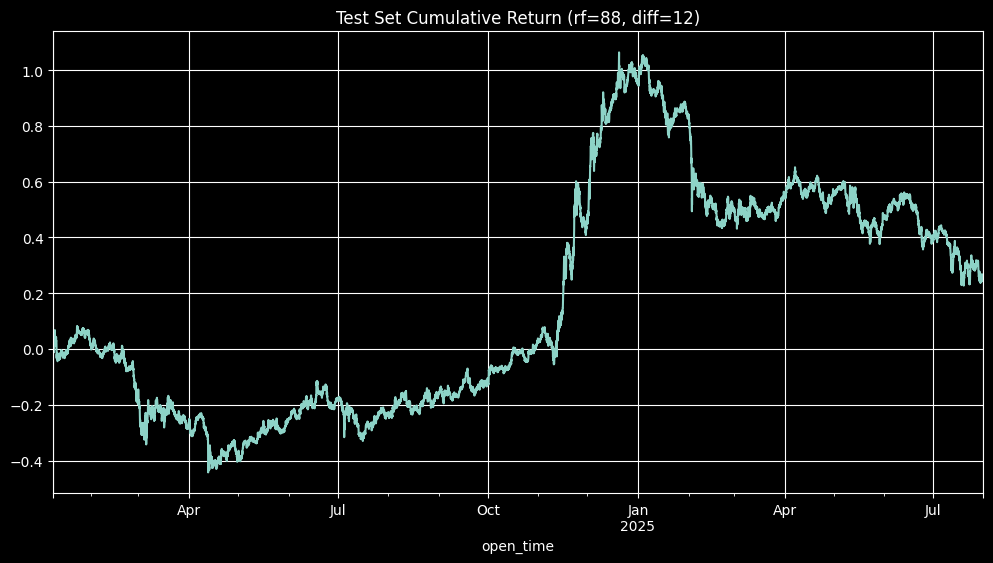

0.31014484222470085


In [ ]:
factor_arr_test = compute_factor_hourly(
    vol=vol_test, close=close_test,
    rets_fwd=rets_fwd_test, diff_score=best_d, rebalance_freq=best_rf,
    long_n=10, fee_rate=0.0005
)

factor_rets_test = pd.Series(factor_arr_test[2*best_rf: -best_rf], index=index_test[2*best_rf: -best_rf])
cum_factor_test = factor_rets_test.cumsum()

plt.figure(figsize=(12, 6))
cum_factor_test.plot()
plt.title(f"Test Set Cumulative Return (rf={best_rf}, diff={best_d})")
plt.grid(True)
plt.show()

print(factor_rets_test.mean() / np.sqrt(np.var(factor_rets_test)) * np.sqrt(365*24))